> Bu, Tom Augspurger'ın CC-BY-4.0 lisanslı 'Effective Pandas' eserinin gönüllü Türkçe çevirisidir. Orijinal: https://github.com/TomAugspurger/effective-pandas

# Performans (Performance)

pandas'ın yaratıcısı [Wes McKinney](https://twitter.com/wesmckinn), performans konusunda adeta saplantılı. Eleman erişimi için mikro optimizasyonlardan, pandas'ın içine hızlı bir hash tablosu [gömmeye](https://github.com/pydata/pandas/tree/master/pandas/src/klib) kadar, onun ve diğerlerinin yoğun emeğinden hepimiz faydalanıyoruz.
Bu yazı esas olarak pandas ve NumPy'ı verimli kullanmaya odaklanacak.

Kasıtlı olarak değinmeyeceğim bir konu ise depolama formatları.
Performans, bir depolama formatı seçerken göz önünde bulundurulması gereken pek çok faktörden sadece biri.
Sadece şunu bilin ki pandas [pek çok formatla](http://pandas.pydata.org/pandas-docs/version/0.18.0/io.html) konuşabiliyor ve performans, taşınabilirlik, veri tipleri, metadata yönetimi gibi konular arasında doğru dengeyi bulan format, [devam eden](http://blog.cloudera.com/blog/2016/03/feather-a-fast-on-disk-format-for-data-frames-for-r-and-python-powered-by-apache-arrow/) bir tartışma konusu.

In [1]:
%matplotlib inline

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if int(os.environ.get("MODERN_PANDAS_EPUB", 0)):
    import prep # noqa

sns.set_style('ticks')
sns.set_context('talk')
pd.options.display.max_rows = 10

## Constructor'lar (Constructors)

Tek bir DataFrame'de birleştirilmesi gereken pek çok benzer kaynağa (diyelim ki bir sürü CSV) sahip olmak oldukça yaygındır. Aynı sonuca giden iki yol vardır:

1. Bir DataFrame başlatıp ona append yapmak
2. Pek çok küçük DataFrame oluşturup sonunda concat yapmak

pandas için ikinci seçenek daha hızlıdır.
DataFrame'e append yapmak, bir listeye append yapmaya göre daha maliyetlidir.
Değerlere bağlı olarak, pandas veriyi farklı bir tipe yeniden döküm (recast) yapmak zorunda kalabilir.
Ve indeks'ler değişmez (immutable) olduğu için, her append yaptığınızda pandas baştan yepyeni bir tane oluşturmak zorunda kalır.

Son bölümde, her eyalet için bir tane olmak üzere bir sürü hava durumu dosyası indirip her birini ayrı bir CSV'ye yazmıştık.
Daha sonra geri gelip bunları aşağıdaki kodu kullanarak okumayı düşünebiliriz.

Deyimsel (idiomatic) python yolu

```python
files = glob.glob('weather/*.csv')
columns = ['station', 'date', 'tmpf', 'relh', 'sped', 'mslp',
           'p01i', 'vsby', 'gust_mph', 'skyc1', 'skyc2', 'skyc3']

# init empty DataFrame, like you might for a list
weather = pd.DataFrame(columns=columns)

for fp in files:
    city = pd.read_csv(fp, columns=columns)
    weather.append(city)
```

Bu, mesela bir tuple listesi oluşturmaya oldukça benzeyen, oldukça standart bir kod.
Tek eleştirilebilecek nokta, sadece bir liste oluşturuyor olsaydınız muhtemelen bir list-comprehension kullanırdınız.
Ama DataFrame-comprehension'lar için özel bir sözdizimimiz yok (keşke olsaydı), bu yüzden "boş bir konteyner başlat, o konteynere append yap" kalıbına geri dönersiniz.

Ama daha iyi, *pandorable*, bir yol var

```python
files = glob.glob('weather/*.csv')
weather_dfs = [pd.read_csv(fp, names=columns) for fp in files]
weather = pd.concat(weather_dfs)
```

Öznel olarak bu daha temiz ve daha güzel.
Daha az satır kod var.
Boş bir DataFrame oluşturmanın bu gereksiz detayına sahip değilsiniz.
Ve nesnel olarak da *pandorable* yol daha hızlı, bunu bir sonraki adımda test edeceğiz.

Aynı DataFrame'i oluşturmak için iki fonksiyon tanımlayacağız. İlki olan `append_df`, boş bir DataFrame oluşturur ve ona append yapar. İkincisi olan `concat_df` ise, pek çok DataFrame oluşturur ve sonunda bunları concat yapar. Ayrıca fonksiyonları birkaç kez çalıştırıp sonuçları kaydeden kısa bir dekoratör (decorator) yazıyoruz.

In [2]:
import time

size_per = 5000
N = 100
cols = list('abcd')

def timed(n=30):
    '''
    Running a microbenchmark. Never use this.
    '''
    def deco(func):
        def wrapper(*args, **kwargs):
            timings = []
            for i in range(n):
                t0 = time.time()
                func(*args, **kwargs)
                t1 = time.time()
                timings.append(t1 - t0)
            return timings
        return wrapper
    return deco
    
@timed(60)
def append_df():
    '''
    The pythonic (bad) way
    '''
    df = pd.DataFrame(columns=cols)
    for _ in range(N):
        df.append(pd.DataFrame(np.random.randn(size_per, 4), columns=cols))
    return df

@timed(60)
def concat_df():
    '''
    The pandorabe (good) way
    '''
    dfs = [pd.DataFrame(np.random.randn(size_per, 4), columns=cols)
           for _ in range(N)]
    return pd.concat(dfs, ignore_index=True)

In [3]:
t_append = append_df()
t_concat = concat_df()

timings = (pd.DataFrame({"Append": t_append, "Concat": t_concat})
             .stack()
             .reset_index()
             .rename(columns={0: 'Time (s)',
                              'level_1': 'Method'}))
timings.head()

,level_0,Method,Time (s)
0,0,Append,0.158359
1,0,Concat,0.093890
2,1,Append,0.150050
3,1,Concat,0.092446
4,2,Append,0.149565


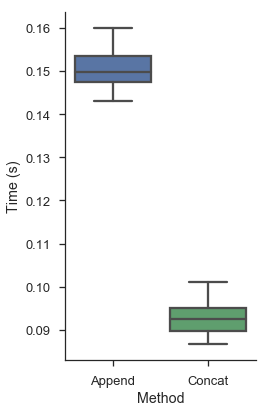

In [4]:
plt.figure(figsize=(4, 6))
sns.boxplot(x='Method', y='Time (s)', data=timings)
sns.despine()
plt.tight_layout()

## Veri Tipleri (Datatypes)

pandas'ın tip sistemi, esasen birkaç ek özellikle (`categorical`, saat dilimli `datetime64`, `timedelta64`) birlikte [NumPy'ınkidir](http://docs.scipy.org/doc/numpy/reference/arrays.scalars.html).
DataFrame'in 2 boyutlu bir NumPy dizisine göre avantajı, tek bir tabloda çeşitli tiplerden sütunlara sahip olabilmesidir.
Bununla birlikte, her sütunun belirli bir veri tipi (dtype) olmalı; tek bir sütun içinde bool'ları int'lerle ve string'lerle karıştırmak istemezsiniz.
Bir kere, bu yavaştır.
Sütunun bir `object` veri tipine (yedek python-nesnesi konteyner tipi) sahip olmasını zorunlu kılar, bu da pandas ya da NumPy'daki tipe özgü optimizasyonlardan hiçbirini alamayacağınız anlamına gelir.
Diğer yandan, bu muhtemelen bir dahaki sefere ele alacağımız düzenli veri (tidy data) ilkelerini ihlal ettiğiniz anlamına gelir.

Ne zaman `object` sütunlarınız olmalı?
NumPy / pandas tip sisteminin isteyebileceğiniz kadar zengin olmadığı birkaç nokta var.
(Şu an için) tam sayı NA'sı yoktur, bu yüzden `NaN` ile temsil edilen herhangi bir eksik değeriniz varsa, aksi halde tam sayı olacak sütununuz float olur.
Ayrıca (`datetime`'dan ayrı olarak) bir `date` veri tipi de yoktur.
Uygulamanızın ihtiyaçlarını düşünün: bir tam sayı olan `1`'i `1.0` olarak ele alabilir misiniz?
`date(2016, 1, 1)`'i `datetime(2016, 1, 1, 0, 0)` olarak ele alabilir misiniz?
Deneyimlerime göre, bu nadiren bir sorun olur; tek istisnası bir veritabanı gibi daha katı bir şemaya sahip bir şeye yazarken olur.
Ama o noktada, artık zaten sayısal işlemler yapmadığınız için, daha az performanslı tiplerden birine dönüştürmek (cast) sorun değildir.

`object` veri tipindeki verinin son durumu metin (text) verisidir.
pandas'ın sabit genişlikte herhangi bir string veri tipi yoktur, bu yüzden python nesneleriyle sıkışıp kalırsınız.
Burada önemli bir istisna var, o da düşük kardinaliteli (low-cardinality) metin verisidir; bunun için `category` veri tipini kullanmak isteyeceksiniz (aşağıya bakın).

Dönüştürülmesi gereken object verisi (string'ler ya da python nesneleri) varsa, [`to_numeric`](http://pandas.pydata.org/pandas-docs/version/0.18.0/generated/pandas.to_numeric.html), [`to_datetime`](http://pandas.pydata.org/pandas-docs/version/0.18.0/generated/pandas.to_datetime.html) ve [`to_timedelta`](http://pandas.pydata.org/pandas-docs/version/0.18.0/generated/pandas.to_timedelta.html) metotlarına göz atın.

## İterasyon, Apply ve Vektörleştirme (Iteration, Apply, And Vectorization)

["Python yavaştır"](https://jakevdp.github.io/blog/2014/05/09/why-python-is-slow/) diye biliyoruz (bu ifade anlamlı olamayacak kadar geniş kapsamlı olduğu için tırnak içine aldım).
Kodunuzun performansını iyileştirmek için, görece basit değişikliklerden, kodunuzu daha düşük seviyeli bir dilde yeniden yazmaya, onu paralelleştirmeye çalışmaya kadar atılabilecek çeşitli adımlar vardır.
Ve pek çok seçeneğiniz olsa da, genellikle izleyeceğiniz bir sıra vardır.

İlk olarak (bunu söylemenin klişe olduğunu biliyorum, ama yine de) kodunuzu benchmark edin (kıyaslayın).
Onu optimize etmeye gerçekten zaman harcamanız gerekip gerekmediğinden emin olun.
Nerelerin yavaş olduğunu [kıyaslamak](https://github.com/nvdv/vprof) ve [görselleştirmek](https://jiffyclub.github.io/snakeviz/) [için](https://github.com/rkern/line_profiler) [pek çok seçenek](https://docs.python.org/3.5/library/timeit.html) vardır. <!-- TR-NOT: Orijinalde 'many options for benchmarking' cümlesi kelime kelime 4 ayrı linke bölünmüştü; Türkçe akışı bozmamak için aynı 4 link, aynı sırayla farklı kelimelere dağıtıldı. -->

İkinci olarak, algoritmanızı gözden geçirin.
Gerekenden daha fazla iş yapmadığınızdan emin olun.
Sık gördüğüm bir örnek, sadece en büyük ya da en küçük `N` öğeyi seçmek için bir dizi üzerinde tam bir sıralama yapmaktır.
pandas'ta bunun için metotlar vardır.

In [5]:
df = pd.read_csv("data/347136217_T_ONTIME.csv")
delays = df['DEP_DELAY']

In [6]:
# Select the 5 largest delays
delays.nlargest(5).sort_values()

112623    1480.0
158136    1545.0
152911    1934.0
60246     1970.0
59719     2755.0
Name: DEP_DELAY, dtype: float64

In [7]:
delays.nsmallest(5).sort_values()

300895   -59.0
235921   -58.0
197897   -56.0
332533   -56.0
344542   -55.0
Name: DEP_DELAY, dtype: float64

`nlargest` ya da `nsmallest`'ı bir sort ile takip ediyoruz (`nlargest/smallest`'ın sonucu sırasızdır), ama 500.000 öğe yerine 5 öğeyi sıralamak çok daha kolaydır. Zamanlamalar (timings) bunu doğruluyor:

In [8]:
%timeit delays.sort_values().tail(5)

29.9 ms ± 1.01 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [9]:
%timeit delays.nlargest(5).sort_values()

7.85 ms ± 142 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


"Doğru algoritmayı kullan" demesi kolay, ama pratikte uygulaması daha zordur, çünkü kullanılacak en iyi algoritmayı gerçekten bulmanız gerekir.
Bu, deneyime bağlıdır.

Optimize edilmesi gereken bir noktada olduğunuzu, doğru algoritmaya sahip olduğunuzu *ve* pandas/numpy/scipy/scikit-learn/statsmodels/... içinde ihtiyacınız olanın hazır, optimize edilmiş bir versiyonunun bulunmadığını varsayarsak, o zaman ne yapılır?

Başvurulacak ilk yer muhtemelen vektörleştirilmiş bir NumPy uygulamasıdır.
Burada vektörleştirme (vectorization), listeler/skalerler üzerinde döngü kurmak yerine doğrudan diziler üzerinde işlem yapmak anlamına gelir.
Bu genellikle Cython gibi bir şeyde yeniden yazmaktan çok daha az iş gerektirir ve sadece NumPy ile pandas'ı *etkili* bir şekilde kullanarak oldukça iyi sonuçlar elde edebilirsiniz.
Her işlem vektörleştirilemese de, çoğu vektörleştirilebilir.

Havalimanları arasındaki [büyük çember mesafesini](https://en.wikipedia.org/wiki/Great-circle_distance) (great-circle distance) hesaplayan bir örnek üzerinden gidelim.
[BTS web sitesinden](http://www.transtats.bts.gov/DL_SelectFields.asp?Table_ID=288&DB_Short_Name=Aviation%20Support%20Tables) havalimanı enlem ve boylam tablosunu alıp bir CSV'ye çıkarın.

In [10]:
from utils import download_airports
import zipfile

In [11]:
if not os.path.exists("data/airports.csv.zip"):
    download_airports()

In [14]:
coord = (pd.read_csv("data/airports.csv.zip", index_col=['AIRPORT'],
                     usecols=['AIRPORT', 'LATITUDE', 'LONGITUDE'])
           .groupby(level=0).first()
           .dropna()
           .sample(n=500, random_state=42)
           .sort_index())

coord.head()

,LATITUDE,LONGITUDE
AIRPORT,,
8F3,33.623889,-101.240833
A03,58.457500,-154.023333
A09,60.482222,-146.582222
A18,63.541667,-150.993889
A24,59.331667,-135.896667


Her ne sebeple olursa olsun, tüm ikili (pairwise) mesafelerle ilgilendiğimizi varsayalım (bunu yönetilebilir kılmak için sadece 500 havalimanlık bir örnekle sınırladım.
Gerçek dünyada *muhtemelen* *tüm* ikili mesafelere ihtiyacınız olmaz ve bir [ağaç](http://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KDTree.html) (tree) kullanmak daha iyi olur. Unutmayın: gerçekte neye ihtiyacınız olduğunu düşünün ve bunun için doğru algoritmayı bulun).

MultiIndex'lerin, verdiğiniz dizilerin [Kartezyen çarpımını](https://en.wikipedia.org/wiki/Cartesian_product) almak için alternatif bir `from_product` constructor'ı vardır.
Ona `coords.index`'i iki kez vereceğiz (kendisiyle Kartezyen çarpımını almak için).
Bu, tüm kombinasyonlardan oluşan bir MultiIndex verir.
`coords`'un biraz yeniden şekillendirilmesiyle (reshaping), tüm enlem/boylam çiftlerine sahip bir DataFrame elde ederiz.

In [45]:
idx = pd.MultiIndex.from_product([coord.index, coord.index],
                                 names=['origin', 'dest'])

pairs = pd.concat([coord.add_suffix('_1').reindex(idx, level='origin'),
                   coord.add_suffix('_2').reindex(idx, level='dest')],
                  axis=1)
pairs.head()

LATITUDE_1  LONGITUDE_1  LATITUDE_2  LONGITUDE_2
origin dest                                                  
8F3    8F3    33.623889  -101.240833   33.623889  -101.240833
       A03    33.623889  -101.240833   58.457500  -154.023333
       A09    33.623889  -101.240833   60.482222  -146.582222
       A18    33.623889  -101.240833   63.541667  -150.993889
       A24    33.623889  -101.240833   59.331667  -135.896667

In [47]:
idx = idx[idx.get_level_values(0) <= idx.get_level_values(1)]

In [48]:
len(idx)

125250

Bunu biraz açacağız, ama gerçek hedefimizi gözden kaçırmayalım: büyük çember mesafesi hesaplamamız.

`add_suffix` (ve `add_prefix`) metodu, sütunları hızlıca yeniden adlandırmak için kullanışlıdır.

In [49]:
coord.add_suffix('_1').head()

,LATITUDE_1,LONGITUDE_1
AIRPORT,,
8F3,33.623889,-101.240833
A03,58.457500,-154.023333
A09,60.482222,-146.582222
A18,63.541667,-150.993889
A24,59.331667,-135.896667


Alternatif olarak `coord.rename(columns=lambda x: x + '_1')` gibi daha genel olan `.rename`'i de kullanabilirsiniz.

Sırada `reindex` var.
Önceki bölümde de bahsettiğim gibi, indeks'ler pandas için hayati önemdedir.
`.reindex`, bir Series ya da DataFrame'i verilen bir indekse hizalamakla ilgilidir.
Bu durumda, orijinal DataFrame'imizi kombinasyonlardan oluşan yeni MultiIndex'e hizalamak için `.reindex`'i kullanıyoruz.
Varsayılan olarak, o indeks etiketi zaten mevcutsa çıktı orijinal değere sahip olur, aksi halde `NaN` olur.
Ek argüman olmadan sadece `coord.reindex(idx)`'i çağırsaydık, hepsi `NaN` olan bir DataFrame elde ederdik.

In [50]:
coord.reindex(idx).head()

LATITUDE  LONGITUDE
origin dest                     
8F3    8F3        NaN        NaN
       A03        NaN        NaN
       A09        NaN        NaN
       A18        NaN        NaN
       A24        NaN        NaN

Bunun nedeni, `coord.index`'te bulunan hiçbir `idx` değerinin olmamasıdır;
bu da mantıklıdır çünkü `coord.index` sadece normal, tek seviyeli bir Index iken, `idx` bir MultiIndex'tir.
Orijinal tek seviyeli Index'ten iki seviyeli `idx`'e geçişi ele almak için `level` anahtar kelimesini kullanıyoruz.

> `level` : int veya isim
>
  Bir seviye boyunca yayılım yapar (broadcast), verilen MultiIndex
    seviyesindeki Index değerleriyle eşleştirir




In [51]:
coord.reindex(idx, level='dest').head()

LATITUDE   LONGITUDE
origin dest                       
8F3    8F3   33.623889 -101.240833
       A03   58.457500 -154.023333
       A09   60.482222 -146.582222
       A18   63.541667 -150.993889
       A24   59.331667 -135.896667

Normal tek seviyeli indeks'leri Çok Seviyeli Indeks'lerle (Multilevel Indexes) karıştıran bir işlem yapmanız gerekirse, bir level anahtar kelime argümanı arayın.
Örneğin, tüm aritmetik metotların (`.mul`, `.add`, vb.) bu argümanı vardır.

Havalimanı `A`'dan `B`'ye olan mesafe, `B`'den `A`'ya olanla aynı olduğu için bu biraz israftır.
Bunu `idx = idx[idx.get_level_values(0) <= idx.get_level_values(1)]` ile kolayca düzeltebilirdik, ama şimdilik bunu görmezden geleceğiz.


Kısa bir ara not: indeks'lerin değeri hakkındaki son yazımla ilgili biraz... şüphecilik diyelim, aldım.
Şüpheciler için alternatif bir versiyon işte:

In [52]:
from itertools import product, chain
coord2 = coord.reset_index()

In [53]:
x = product(coord2.add_suffix('_1').itertuples(index=False),
            coord2.add_suffix('_2').itertuples(index=False))
y = [list(chain.from_iterable(z)) for z in x]

df2 = (pd.DataFrame(y, columns=['origin', 'LATITUDE_1', 'LONGITUDE_1',
                                'dest', 'LATITUDE_1', 'LONGITUDE_2'])
       .set_index(['origin', 'dest']))
df2.head()

LATITUDE_1  LONGITUDE_1  LATITUDE_1  LONGITUDE_2
origin dest                                                  
8F3    8F3    33.623889  -101.240833   33.623889  -101.240833
       A03    33.623889  -101.240833   58.457500  -154.023333
       A09    33.623889  -101.240833   60.482222  -146.582222
       A18    33.623889  -101.240833   63.541667  -150.993889
       A24    33.623889  -101.240833   59.331667  -135.896667

Bu da okunabilir (sonuçta Python), gerçi biraz daha yavaş.
Bana göre `.reindex` metodu daha doğal görünüyor.
Düşünce sürecim şöyleydi: "Origin & destination'ın tüm kombinasyonlarına ihtiyacım var (`MultiIndex.from_product`).
Şimdi bu orijinal DataFrame'i bu yeni MultiIndex'e hizalamam gerekiyor (`coords.reindex`)."

Bu ara notu geride bırakıp, büyük çember mesafesi hesaplamamıza geri dönelim.
İlk uygulamamız saf python.
Algoritmanın kendisi çok önemli değil, önemli olan skalerler üzerinde matematik işlemleri yapıyor olmamız.

In [54]:
import math

def gcd_py(lat1, lng1, lat2, lng2):
    '''
    Calculate great circle distance between two points.
    http://www.johndcook.com/blog/python_longitude_latitude/
    
    Parameters
    ----------
    lat1, lng1, lat2, lng2: float
    
    Returns
    -------
    distance:
      distance from ``(lat1, lng1)`` to ``(lat2, lng2)`` in kilometers.
    '''
    # python2 users will have to use ascii identifiers (or upgrade)
    degrees_to_radians = math.pi / 180.0
    ϕ1 = (90 - lat1) * degrees_to_radians
    ϕ2 = (90 - lat2) * degrees_to_radians
    
    θ1 = lng1 * degrees_to_radians
    θ2 = lng2 * degrees_to_radians
    
    cos = (math.sin(ϕ1) * math.sin(ϕ2) * math.cos(θ1 - θ2) +
           math.cos(ϕ1) * math.cos(ϕ2))
    # round to avoid precision issues on identical points causing ValueErrors
    cos = round(cos, 8)
    arc = math.acos(cos)
    return arc * 6373  # radius of earth, in kilometers

İkinci uygulama NumPy kullanıyor.
numpy'ın (muhtemelen bir sabitle, $\frac{\pi}{180}$ ile, çarpmaktan biraz daha yavaş olan) yerleşik bir `deg2rad` kolaylık fonksiyonuna sahip olması dışında, temelde yaptığımız tek şey `math` önekini `np` ile değiştirmek.
NumPy'ın yayılımı (broadcasting) sayesinde, skalerler ya da uyumlu şekle sahip diziler üzerinde çalışan kod yazabiliriz.

In [55]:
def gcd_vec(lat1, lng1, lat2, lng2):
    '''
    Calculate great circle distance.
    http://www.johndcook.com/blog/python_longitude_latitude/
    
    Parameters
    ----------
    lat1, lng1, lat2, lng2: float or array of float
    
    Returns
    -------
    distance:
      distance from ``(lat1, lng1)`` to ``(lat2, lng2)`` in kilometers.
    '''
    # python2 users will have to use ascii identifiers
    ϕ1 = np.deg2rad(90 - lat1)
    ϕ2 = np.deg2rad(90 - lat2)
    
    θ1 = np.deg2rad(lng1)
    θ2 = np.deg2rad(lng2)
    
    cos = (np.sin(ϕ1) * np.sin(ϕ2) * np.cos(θ1 - θ2) +
           np.cos(ϕ1) * np.cos(ϕ2))
    arc = np.arccos(cos)
    return arc * 6373

python versiyonunu DataFrame'imiz üzerinde kullanmak için, ya iterasyon yapabiliriz...

In [56]:
%%time
pd.Series([gcd_py(*x) for x in pairs.itertuples(index=False)],
          index=pairs.index)

CPU times: user 823 ms, sys: 9.51 ms, total: 833 ms
Wall time: 832 ms


origin  dest
8F3     8F3         0.000000
        A03      4744.967448
        A09      4407.533212
        A18      4744.593127
        A24      3820.092688
                    ...     
ZZU     YUY     12643.665960
        YYL     13687.592278
        ZBR      4999.647307
        ZXO     14925.531303
        ZZU         0.000000
Length: 250000, dtype: float64

Ya da `DataFrame.apply`'ı kullanabiliriz.

In [57]:
%%time
r = pairs.apply(lambda x: gcd_py(x['LATITUDE_1'], x['LONGITUDE_1'],
                                 x['LATITUDE_2'], x['LONGITUDE_2']), axis=1);

CPU times: user 14.4 s, sys: 58.6 ms, total: 14.5 s
Wall time: 14.5 s


Ama görebileceğiniz gibi, özellikle `axis=1` ile (fonksiyonu her satırda çağırarak) apply kullanmak istemezsiniz. Arka planda veri tiplerini (dtype) ele almak ve bu durumda salt ek yük (overhead) olan doğru çıktı şeklini (shape) tahmin etmeye çalışmakla çok daha fazla iş yapıyor. Üstüne üstlük, içeride esasen bir for döngüsü kullanmak zorunda.

`DataFrame.apply`'ı *nadiren* kullanmak isteyeceksiniz ve neredeyse hiçbir zaman `axis=1` ile kullanmamalısınız. Dizileri (array) alan fonksiyonlar yazıp bunları doğrudan geçirmek daha iyidir. Vektörleştirilmiş versiyonda yaptığımız gibi

In [58]:
%%time
r = gcd_vec(pairs['LATITUDE_1'], pairs['LONGITUDE_1'],
            pairs['LATITUDE_2'], pairs['LONGITUDE_2'])

CPU times: user 34.9 ms, sys: 21.1 ms, total: 56 ms
Wall time: 38.9 ms


/Users/taugspurger/miniconda3/envs/modern-pandas/lib/python3.6/site-packages/ipykernel_launcher.py:24: RuntimeWarning: invalid value encountered in arccos


In [60]:
r.head()

origin  dest
8F3     8F3        0.000000
        A03     4744.967484
        A09     4407.533240
        A18     4744.593111
        A24     3820.092639
dtype: float64

Öğretirken "kolay" kelimesini kullanmamaya çalışırım, ama o optimizasyon kolaydı, değil mi?
Öyleyse neden, vektörleştirilmiş versiyon mevcutken bile, kendi kodumda ve başkalarının kodunda `apply` kullanımlarıyla karşılaşıyorum?
Zorluk, yayılımı (broadcasting) bilmekte ve nerede uygulanacağını görmekte yatıyor.

Örneğin, [lifetimes](https://github.com/CamDavidsonPilon/lifetimes) kütüphanesinin README'sinde (Cam Davidson Pilon tarafından yazılmıştır; kendisi ayrıca [Bayesian Methods for Hackers](https://github.com/CamDavidsonPilon/Probabilistic-Programming-and-Bayesian-Methods-for-Hackers), [lifelines](https://github.com/CamDavidsonPilon/lifelines) ve [Data Origami](https://dataorigami.net)'nin de yazarıdır) eskiden [bu metodu](https://github.com/CamDavidsonPilon/lifetimes/blob/5b4f7de0720413b6951ac0a4b0082bd50255a231/lifetimes/estimation.py#L249) bir `DataFrame.apply`'a geçiren bir örnek vardı.

```python
data.apply(lambda r: bgf.conditional_expected_number_of_purchases_up_to_time(
    t, r['frequency'], r['recency'], r['T']), axis=1
)
```

[Bağlantısını verdiğim](https://github.com/CamDavidsonPilon/lifetimes/blob/5b4f7de0720413b6951ac0a4b0082bd50255a231/lifetimes/estimation.py#L249) fonksiyona bakarsanız, `scipy.special`'daki bir negatif log-olabilirlik (negative log likelihood) ve Gamma fonksiyonunu içeren oldukça karmaşık bir hesaplama yaptığını görürsünüz.
Ama en önemlisi, bu fonksiyon zaten vektörleştirilmişti.
Örneği, fonksiyonu her satıra uygulamak yerine, dizileri (bu durumda Series'leri) doğrudan fonksiyona geçirecek şekilde değiştirebildik.

```python
bgf.conditional_expected_number_of_purchases_up_to_time(
    t, data['frequency'], data['recency'], data['T']
)
```

Bu bize örnek veri kümesinde 30 kat daha fazla hızlanma sağladı.
Bunu gündeme getiriyorum çünkü bir denklemi koda çevirip "Tamam, şimdi bu fonksiyonu her satıra uygulamam gerekiyor" diye düşünmek çok doğal; bu yüzden `DataFrame.apply`'a başvurursunuz.
Bunun yerine sadece NumPy dizisini ya da Series'in kendisini geçirip geçiremeyeceğinize bakın.

Her işlem bu kadar kolay vektörleştirilemez.
Bazı işlemler doğası gereği yinelemelidir ve devam edebilmek için çevresindeki hesaplamaların sonuçlarına dayanır. Böyle durumlarda, bilimsel python kütüphanelerinden birinin bunu sizin için verimli bir şekilde uygulamış olmasını umabilir, ya da Numba / C / Cython / Fortran kullanarak kendi çözümünüzü yazabilirsiniz.

Diğer örnekler, vektörleştirmek için biraz daha fazla düşünce ya da bilgi gerektirir.
Jeff Reback'in PyData London konuşmasından alınan, bir veri kümesini her grup için ortalamayı çıkarıp standart sapmaya bölerek grup bazında normalize eden [şu](http://nbviewer.jupyter.org/github/jreback/pydata2015-london/blob/master/notebooks/idioms.ipynb)
örneğe bakalım.

In [61]:
import random

def create_frame(n, n_groups):
    # just setup code, not benchmarking this
    stamps = pd.date_range('20010101', periods=n, freq='ms')
    random.shuffle(stamps.values)    
    return pd.DataFrame({'name': np.random.randint(0,n_groups,size=n),
                         'stamp': stamps,
                         'value': np.random.randint(0,n,size=n),
                         'value2': np.random.randn(n)})


df = create_frame(1000000,10000)

def f_apply(df):
    # Typical transform
    return df.groupby('name').value2.apply(lambda x: (x-x.mean())/x.std())

def f_unwrap(df):
    # "unwrapped"
    g = df.groupby('name').value2
    v = df.value2
    return (v-g.transform(np.mean))/g.transform(np.std)


Zamanlayınca, "unwrapped" (açılmış) versiyonun oldukça daha iyi performans aldığını görüyoruz.

In [ ]:
%timeit f_apply(df)

In [ ]:
%timeit f_unwrap(df)

pandas'ın GroupBy nesneleri, mean, sum gibi yaygın fonksiyonlara yapılan çağrıları yakalar ve bunları optimize edilmiş Cython versiyonlarıyla değiştirir.
Bu yüzden unwrapped (açılmamış) `.transform(np.mean)` ve `.transform(np.std)` hızlıdır, ama `.apply(lambda x: x - x.mean()/x.std())` içindeki `x.mean` ve `x.std` hızlı değildir.

`Groupby.apply` her zaman var olacak, çünkü maksimum esneklik sunar. [Her grup için bir model uydurup süreç içinde ek sütunlar oluşturmanız](http://stackoverflow.com/q/35924126/1889400) gerekiyorsa, bunu halledebilir. Sadece en hızlısı olmayabilir (ki bu bazen sorun olmayabilir).

Bu son örnek kabul etmek gerekirse niş bir örnek.
pandas'ta, doğal olan `.transform((x - x.mean()) / x.std())` yapmanın, daha az bariz olan alternatiften daha yavaş olduğu pek fazla yer olmadığını düşünmek isterim.
İdeal olarak kullanıcının, GroupBy'ın yaygın metotların özel hızlı uygulamalarına sahip olduğunu bilmesine gerek kalmamalı.
Ama şu an durumumuz bu.

## Kategorikler (Categoricals)


[Jan Schulz](https://twitter.com/janschulz), [Jeff Reback](https://twitter.com/janschulz) ve diğerlerinin harika çalışmaları sayesinde, pandas 0.15 yeni bir [Categorical](http://pandas.pydata.org/pandas-docs/version/0.18.0/categorical.html) veri tipi kazandı. Categorical'lar sadece verimlilik dışında pek çok nedenden ötürü de güzeldir, ama burada bu konuya odaklanacağız.

Categorical'lar, düşük *kardinaliteye* (cardinality) sahip verileri (genellikle string'leri) — yani dizinin boyutuna göre görece az sayıda farklı değeri olan verileri — temsil etmenin verimli bir yoludur. İç yapıda, bir Categorical, kategorileri bir kez saklar ve hangi kategorinin orada olduğunu belirten, sadece tam sayı olan bir `codes` dizisi tutar. Bir `code` saklamak bir `category` saklamaktan daha ucuz olduğu için bellekten tasarruf ederiz (bir sonraki bölümde gösterilecek).



In [ ]:
import string

s = pd.Series(np.random.choice(list(string.ascii_letters), 100000))
print('{:0.2f} KB'.format(s.memory_usage(index=False) / 1000))

In [ ]:
c = s.astype('category')
print('{:0.2f} KB'.format(c.memory_usage(index=False) / 1000))

Bellekten tasarruf etmenin ötesinde, kodlara ve sabit bir kategori kümesine sahip olmak, pandas'ın ve başkalarının faydalanabileceği bir sürü algoritmik optimizasyon sunar.

[Matthew Rocklin](https://twitter.com/mrocklin)'in, categorical kullanma ve genel olarak kod optimize etme üzerine çok güzel bir [yazısı](http://matthewrocklin.com/blog/work/2015/06/18/Categoricals) var.

## Daha İleriye (Going Further)

pandas dokümantasyonunda, bir hesaplamayı hızlandırmak için Cython ya da `numba` kullanmaya odaklanan bir [performansı artırma](http://pandas.pydata.org/pandas-docs/version/0.18.0/enhancingperf.html) bölümü var. Ben daha çok, doğru algoritmayı seçmek, kodunuzu vektörleştirmek ve pandas ya da numpy'ı daha etkili kullanmak gibi kolay elde edilebilir kazanımlara (lower-hanging fruit) odaklandım. Bunlar yeterli gelmezse, daha ileri optimizasyonlar da mevcut.

## Özet (Summary)

Bu yazı, kendi son derece optimize edilmiş kodunuzu yazmaktan çok, numpy ve pandas'ı etkili bir şekilde nasıl kullanacağınızla ilgiliydi.
Günlük veri analizi işimde, bir cython eklentisi yazıp derlemek zamana değmez.
Önemli olan konularda (büyük dizilerde etiket araması, groupby ve merge'ler için factorization, sayısal işlemler) hızlı olması için pandas'a güvenmeyi tercih ederim.
pandas'ın işleri hızlandırmak için ne yaptığı hakkında daha fazla bilgi edinmek isterseniz, pandas'ın iç yapısı üzerine Jeff Tratner'ın PyData Seattle [konuşmasına](http://www.jeffreytratner.com/slides/pandas-under-the-hood-pydata-seattle-2015.pdf) göz atın.

Bir dahaki sefere farklı bir optimizasyon türüne bakacağız: verimli veri analizini kolaylaştırmak için Düzenli Veri (Tidy Data) ilkelerini kullanmak.